In [5]:
import os
from typing import Annotated

from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.graph import START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from typing_extensions import TypedDict

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [6]:
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
class State(TypedDict):
    # `messages` holds the running conversation as a list. Because it's
    # annotated with `add_messages`, updates to this field are merged by
    # appending the new message(s) onto the existing list rather than
    # replacing the whole list outright.
    messages: Annotated[list, add_messages]

In [9]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 91.2
    }.get(symbol, 0.0)

tools = [get_stock_price]


llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm_with_tools = llm.bind_tools(tools)

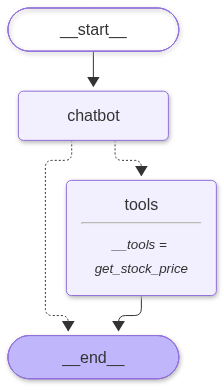

In [10]:
def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)

graph = builder.compile()

graph

`tools_condition` is a prebuilt routing function from langgraph.prebuilt. It inspects the last message in state["messages"] and decides where to go next:

If the last AI message has tool_calls → returns "tools"
Otherwise → returns END

In [13]:
state = graph.invoke({"messages": [{"role": "user", "content": "What is the price of AAPL stock right now?"}]})
print(state["messages"][-1].content)

100.4


In [14]:
state

{'messages': [HumanMessage(content='What is the price of AAPL stock right now?', additional_kwargs={}, response_metadata={}, id='541a0db5-0114-44d8-a07a-e6ba8b3bce4b'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'y2y3y329f', 'function': {'arguments': '{"symbol":"AAPL"}', 'name': 'get_stock_price'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 301, 'total_tokens': 329, 'completion_time': 0.145472758, 'completion_tokens_details': None, 'prompt_time': 0.027414074, 'prompt_tokens_details': None, 'queue_time': 0.13928595, 'total_time': 0.172886832}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_3f7cb2e2dd', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a22218-2f05-732f-96fa-c831b249d1af-0', tool_calls=[{'name': 'get_stock_price', 'args': {'symbol': 'AAPL'}, 'id': 'y2y3y329f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

In [15]:
state = graph.invoke({"messages": [{"role": "user", "content": "Who invented theory of relativity? print person name only"}]})
print(state["messages"][-1].content)

Albert Einstein


In [16]:
state

{'messages': [HumanMessage(content='Who invented theory of relativity? print person name only', additional_kwargs={}, response_metadata={}, id='623f4b89-d8c5-4e39-b21d-853a5b676acf'),
  AIMessage(content='Albert Einstein', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 3, 'prompt_tokens': 301, 'total_tokens': 304, 'completion_time': 0.006060021, 'completion_tokens_details': None, 'prompt_time': 0.024291234, 'prompt_tokens_details': None, 'queue_time': 0.053681073, 'total_time': 0.030351255}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a22218-70b6-769e-9009-381fc7ca7941-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 301, 'output_tokens': 3, 'total_tokens': 304})]}

In [10]:
msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]})
print(state["messages"][-1].content)

200.3


### 🤔 Before you move on
Look closely at the last answer above — for a multi-step buy question, the graph handed back a raw tool result instead of a real final answer. That's because there's no edge routing from the `tools` node back to `chatbot`: once a tool runs, the graph just stops there. What single edge would turn this into a real loop, where the model sees the tool's result and decides what to do next (call another tool, or answer)? That's the exact fix in `5_tool_call_agent.ipynb`.